# 02 - Manifold | scFates principal curve (non-branching)
Gate 1 called the manifold continuous and non-branching. Fit a scFates **curve** (not a tree -
no re-embedding of a linear compartment), verify it is **fold-free** by rendering its edges,
derive the **root** from the signatures' developmental order (Gast/pSom-high origin; Crest is
*late*), infer pseudotime, and fix a house linear orientation.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from numpy.linalg import svd
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

manifold: 1435 cells on the joint embedding (full component)
UMAP aspect ratio (major/minor std) = 1.62  (~1 blob, no re-embedding needed)


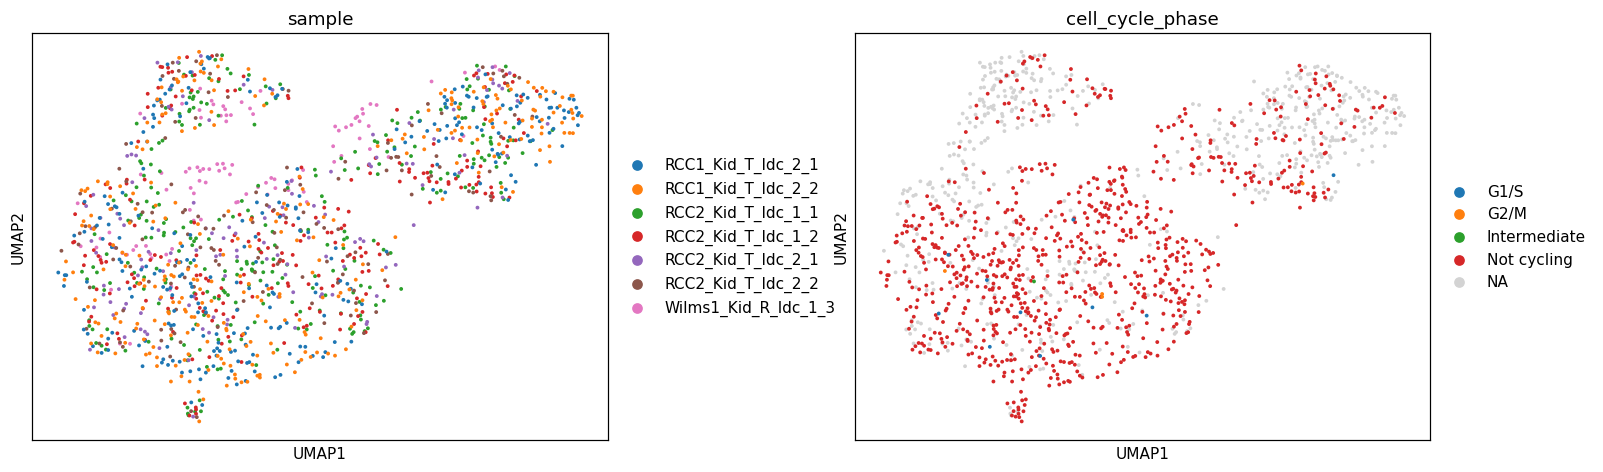

In [ ]:
# load processed data; confirm single blob (not an elongated strip that a fresh UMAP would fold)
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
sub = adata.copy()
print('manifold:', sub.shape[0], 'cells on the joint embedding (full component)')
xy = sub.obsm['X_umap']; c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std) = {s[0]/s[1]:.2f}  (~1 blob, no re-embedding needed)')
sc.pl.umap(sub, color=['sample','cell_cycle_phase'], size=25, wspace=.3)

In [ ]:
# topology probe: fit curve on the existing UMAP, measure forks + fold self-approach ratio
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.84 (>1 = fold-free)


In [ ]:
# recompute smoothed signatures on the graph (for reading developmental order at the tips)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(sub.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(sub.var_names)]
    sc.tl.score_genes(sub, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (sub.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = sub.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): sub.obs[lab+'_sm'] = S[:,j]

Gast: 66/81 genes present
pSom: 75/98 genes present
Crest: 96/104 genes present


In [ ]:
# derive root from developmental order: Gast/pSom-high, Crest-low tip (Crest is LATE)
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for t in tps:
    m = np.isin(hard, np.where(D[t]<=3)[0])
    info[t] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {t}: Gast={info[t][0]:+.4f} pSom={info[t][1]:+.4f} Crest={info[t][2]:+.4f}')
root = int(max(tps, key=lambda t: info[t][1] - info[t][2]))  # pSom-high, Crest-low origin
print('derived root = tip', root, '(pSom-high, Crest-low developmental origin; Crest is late)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0136 pSom=+0.0507 Crest=-0.0333
tip 2: Gast=-0.0112 pSom=+0.0377 Crest=-0.0222
derived root = tip 0 (pSom-high, Crest-low developmental origin; Crest is late)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.385 p=8.7e-52
  pSom_sm: rho=-0.748 p=1.4e-257
  Crest_sm: rho=+0.716 p=7.2e-226


In [ ]:
# name milestones: developmental origin (root) -> terminus
mil = sub.obs['milestones'].astype(str)
tvals = sub.obs.groupby('milestones', observed=True)['t'].mean().sort_values()
rename = {}
for i,(m,_) in enumerate(tvals.items()):
    rename[m] = 'pSom/Body origin' if i==0 else ('Neural-Crest terminus' if i==len(tvals)-1 else f'mid_{i}')
sub.obs['milestones'] = mil.map(rename).astype('category')
print('milestones (low->high pseudotime):', list(tvals.index), '->', [rename[m] for m in tvals.index])

milestones (low->high pseudotime): ['0', '2'] -> ['pSom/Body origin', 'Neural-Crest terminus']


single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)


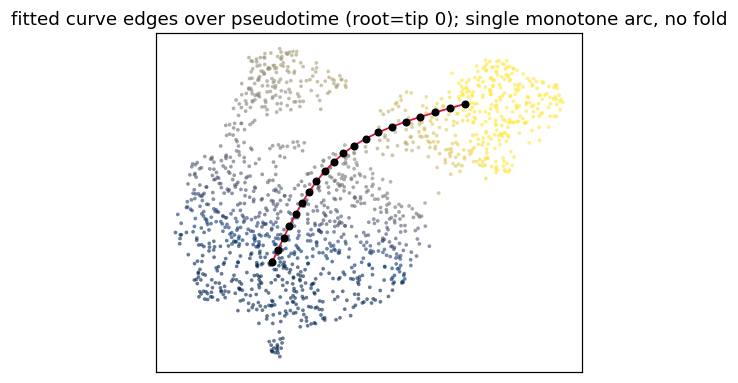

In [ ]:
# FOLD CHECK - render fitted curve edges over pseudotime (do NOT judge topology blind)
F = sub.uns['graph']['F'].T; Bc = np.asarray(sub.uns['graph']['B'])
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], s=6, c=sub.obs['t'], cmap='cividis', alpha=.6, lw=0)
ii,jj = np.where(np.triu(Bc>0))
for a,b in zip(ii,jj): ax.plot([F[a,0],F[b,0]],[F[a,1],F[b,1]], '-', color='crimson', lw=1.2)
ax.scatter(F[:,0],F[:,1], s=18, c='k', zorder=5)
ax.set_title(f'fitted curve edges over pseudotime (root=tip {root}); single monotone arc, no fold')
ax.set_xticks([]); ax.set_yticks([])
print('single monotone arc, no self-crossing -> fold-free (matches self-approach ratio)')

In [ ]:
# derive house linear orientation: low pseudotime on the left (consistent across panels)
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
sx = 1.0 if np.corrcoef(xy[:,0], t)[0,1] > 0 else -1.0
xyr = np.column_stack([sx*xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
assert r > 0, f'orientation derivation failed (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr; sub.uns['orient_sx'] = sx
print(f'orientation: X_umap_lin = ({sx:+.0f}*raw_x, raw_y) [derived sign]; corr(x_lin, pseudotime) = {r:+.2f} (low pt on left)')

orientation: X_umap_lin = (+1*raw_x, raw_y) [derived sign]; corr(x_lin, pseudotime) = +0.78 (low pt on left)


In [ ]:
# save manifold
if 'epg' in sub.uns:
    sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', sub.shape)

saved manifold.h5ad (1435, 18530)


saved manifold.pdf | cells: 1435


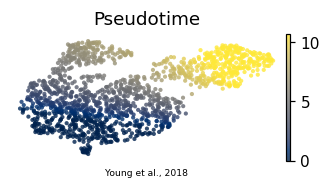

In [ ]:
# save manifold embedding figure (house 3.5x1.5 linear aspect, pseudotime colour)
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Young et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf | cells:', sub.n_obs)